# Notebook 4 — Analisis Gabungan Marine Heatwave (MHW) dan Chlorophyll-a di Perairan NTT

**Proyek:** Analisis Hubungan Dinamika Termal Ekstrem dan Produktivitas Primer Laut di NTT  
**Periode Analisis Gabungan:** 2000–2020 (Periode Tumpang Tindih Terverifikasi)  
**Wilayah:** Perairan NTT (Bounding Box: 117.5°–127.5°BT, -13.0°–-7.0°LS)  

---

## Ringkasan Tujuan
1. Menyelaraskan periode temporal tumpang tindih antara data SST harian (2000–2020) dan Chlorophyll-a harian (2000–2020), menghasilkan rentang analisis 2000–2020 (21 tahun).
2. Melakukan penyelarasan grid spasial secara transparan: mengagregasi resolusi tinggi Chlorophyll-a (~4 km) ke grid resolusi SST (0.25° ≈ 25 km) dengan metode perata-rataan area (*co-binning*) yang mempertahankan integritas data hilang.
3. Mengklasifikasikan kondisi harian dan sel grid ke dalam status MHW dan Non-MHW berdasarkan katalog kejadian Hobday et al. (2016).
4. Membandingkan konsentrasi dan anomali chlorophyll-a pada kondisi MHW versus Non-MHW, baik secara keseluruhan maupun secara terstratifikasi per musim (Monsun Barat vs Monsun Timur/Upwelling).
5. Menguji signifikansi perbedaan distribusi menggunakan uji statistik non-parametrik (Mann-Whitney U Test).
6. Mengevaluasi studi kasus spasial respon klorofil-a terhadap kejadian MHW terkuat.

> **Batas Interpretasi & Batasan Kausalitas (PRD):**
> - **Bukan Bukti Kausalitas:** Perbedaan pola klorofil-a pada saat MHW tidak membuktikan hubungan sebab-akibat langsung. Hubungan ini diinterpretasikan sebagai kopling oseanografi fisik-biologis (misalnya pemanasan permukaan yang memperkuat stratifikasi dan menekan pencampuran vertikal/upwelling nutrien).
> - **Faktor Perancu (*Confounding Factors*):** Dinamika massa air Arlindo (*Indonesian Throughflow*), angin permukaan, dan tutupan awan musiman turut mempengaruhi estimasi observasi satelit.

---
## 1. Konfigurasi dan Impor Pustaka

In [1]:
import sys
import os
import warnings
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.ticker as ticker
from scipy import stats

warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=RuntimeWarning)

notebook_dir = Path(os.path.abspath(''))
project_root = notebook_dir.parent if notebook_dir.name == 'notebooks' else notebook_dir
sys.path.insert(0, str(project_root / 'config'))

import project_config as cfg

print("=" * 60)
print("KONFIGURASI NOTEBOOK 4 — ANALISIS GABUNGAN MHW & CHL-A")
print("=" * 60)
print(f"SST Merged Input : {cfg.SST_MERGED_OUTPUT}")
print(f"Chl-a Merged Input: {cfg.CHLA_MERGED_OUTPUT}")
print(f"MHW Events Input : {cfg.MHW_EVENTS_OUTPUT}")
print(f"Combined Output  : {cfg.COMBINED_OUTPUT}")
print(f"Grid Referensi   : {cfg.COMBINED_GRID} (0.25°)")

KONFIGURASI NOTEBOOK 4 — ANALISIS GABUNGAN MHW & CHL-A
SST Merged Input : G:\My Drive\KLIMTROP\PBL\data\processed\sst_daily_2000_2020_ntt.nc
Chl-a Merged Input: G:\My Drive\KLIMTROP\PBL\data\processed\chlorophyll_a_daily_ntt.nc
MHW Events Input : G:\My Drive\KLIMTROP\PBL\data\processed\mhw_events_ntt.csv
Combined Output  : G:\My Drive\KLIMTROP\PBL\data\processed\mhw_chla_aligned_daily_ntt.nc
Grid Referensi   : sst (0.25°)


---
## 2. Pemuatan Dataset dan Penentuan Periode Tumpang Tindih (Overlap)

In [2]:
# Buka dataset input
ds_sst = xr.open_dataset(cfg.SST_MERGED_OUTPUT)
ds_chla = xr.open_dataset(cfg.CHLA_MERGED_OUTPUT)
df_events = pd.read_csv(cfg.MHW_EVENTS_OUTPUT)

print(f"Dataset SST  : {str(ds_sst.time.values[0])[:10]} s.d. {str(ds_sst.time.values[-1])[:10]} ({len(ds_sst.time)} hari)")
print(f"Dataset Chl-a: {str(ds_chla.time.values[0])[:10]} s.d. {str(ds_chla.time.values[-1])[:10]} ({len(ds_chla.time)} hari)")
print(f"Katalog MHW  : {len(df_events)} kejadian teridentifikasi")

# Tentukan periode tumpang tindih
t_start = max(ds_sst.time.values[0], ds_chla.time.values[0])
t_end = min(ds_sst.time.values[-1], ds_chla.time.values[-1])

print(f"\nPeriode Overlap Analisis Gabungan:")
print(f"  Mulai   : {str(t_start)[:10]}")
print(f"  Selesai : {str(t_end)[:10]}")

# Potong kedua dataset ke periode overlap
ds_sst_sub = ds_sst.sel(time=slice(t_start, t_end))
ds_chla_sub = ds_chla.sel(time=slice(t_start, t_end))
print(f"Jumlah hari overlap yang dianalisis: {len(ds_sst_sub.time)} hari (2000–2020)")

Dataset SST  : 2000-01-01 s.d. 2020-12-31 (7671 hari)
Dataset Chl-a: 2000-01-01 s.d. 2020-12-31 (7669 hari)
Katalog MHW  : 43 kejadian teridentifikasi

Periode Overlap Analisis Gabungan:
  Mulai   : 2000-01-01
  Selesai : 2020-12-31
Jumlah hari overlap yang dianalisis: 7670 hari (2000–2020)


---
## 3. Penyelarasan Grid Spasial: Agregasi Chlorophyll-a ke Grid SST (0.25°)

Sesuai prinsip PRD, resolusi asli kedua sensor berbeda:
- **SST (NOAA OISST v2.1):** 0.25° x 0.25° (~25 km)
- **Chlorophyll-a (ESA CCI OC v6.0):** 0.0417° x 0.0417° (~4 km)

Pendekatan penyelarasan: mengagregasikan piksel klorofil-a ke dalam setiap kotak grid SST 0.25° menggunakan interpolasi bilinear / area-averaging dengan `interp_like`. Piksel darat/missing dipertahankan sebagai NaN.

In [3]:
# Penyelarasan grid chlorophyll-a ke grid SST (0.25deg) menggunakan block-average
# Catatan metode: bilinear interp tidak cocok untuk data dengan banyak NaN (tutupan awan).
# Block-average (nanmean) mengakomodasi missing value: suatu piksel SST tetap valid
# jika ada minimal satu piksel 4km dalam kotak 0.25deg yang tidak bernilai NaN.
print("Melakukan penyelarasan grid klorofil-a ke grid SST (0.25 deg) via block-average...")
print("=" * 65)

chla_lats = ds_chla_sub.lat.values
chla_lons = ds_chla_sub.lon.values
sst_lats = ds_sst_sub.lat.values
sst_lons = ds_sst_sub.lon.values
half = 0.125  # setengah resolusi SST

# Pra-hitung indeks bin lat/lon untuk efisiensi
lat_bin_idx = []
lon_bin_idx = []
for i, slat in enumerate(sst_lats):
    lat_bin_idx.append(np.where((chla_lats >= slat - half) & (chla_lats < slat + half))[0])
for j, slon in enumerate(sst_lons):
    lon_bin_idx.append(np.where((chla_lons >= slon - half) & (chla_lons < slon + half))[0])

n_time = len(ds_chla_sub.time)
chla_regrid_arr = np.full((n_time, len(sst_lats), len(sst_lons)), np.nan, dtype=np.float32)

for t in range(n_time):
    chla_day = ds_chla_sub['chlor_a'].isel(time=t).values
    for i, li in enumerate(lat_bin_idx):
        for j, lj in enumerate(lon_bin_idx):
            block = chla_day[np.ix_(li, lj)]
            if (~np.isnan(block)).any():
                chla_regrid_arr[t, i, j] = float(np.nanmean(block))
    if t % 500 == 0:
        pct = 100 * t / n_time
        n_valid = int((~np.isnan(chla_regrid_arr[t])).sum())
        print(f"  Progres: {t}/{n_time} hari ({pct:.1f}%) - hari ini {n_valid} piksel valid")

print(f"  Selesai: {n_time} hari diproses.")

# Normalisasi timestamp chla ke 12:00 (konsisten dengan SST OISST)
chla_times_noon = pd.DatetimeIndex([
    pd.Timestamp(t).replace(hour=12)
    for t in pd.DatetimeIndex(ds_chla_sub.time.values)
]).values

# Susun DataArray regridded
chla_regrid_da = xr.DataArray(
    chla_regrid_arr,
    coords={"time": chla_times_noon, "lat": sst_lats, "lon": sst_lons},
    dims=["time", "lat", "lon"],
    attrs={
        "long_name": ds_chla_sub['chlor_a'].attrs.get("long_name", "Chlorophyll-a"),
        "units": "mg/m3",
        "regrid_method": "block-average (nanmean) from 4km to 0.25deg SST grid",
        "source_resolution": "~4 km (0.0417 deg)",
        "target_resolution": "0.25 deg (~25 km)",
        "note": "Piksel NaN berarti tidak ada data 4km yang valid dalam kotak 0.25deg (tutupan awan atau daratan)."
    }
)

# Selaraskan waktu antara SST dan chlorophyll-a (inner join pada waktu)
sst_times_set = set(pd.DatetimeIndex(ds_sst_sub.time.values))
chla_times_set = set(pd.DatetimeIndex(chla_times_noon))
common_times = sorted(sst_times_set & chla_times_set)
print(f"\nTotal hari waktu bersama (SST & Chla): {len(common_times)}")

ds_sst_aligned = ds_sst_sub.sel(time=np.array(common_times, dtype='datetime64[ns]'))
chla_regrid_aligned = chla_regrid_da.sel(time=np.array(common_times, dtype='datetime64[ns]'))

# Buat dataset gabungan
ds_combined = xr.Dataset(
    data_vars={
        'sst': ds_sst_aligned['sst'],
        'chlor_a': chla_regrid_aligned
    },
    attrs={
        'title': 'Dataset Gabungan SST dan Chlorophyll-a Perairan NTT',
        'sst_source': 'NOAA OISST v2.1 AVHRR-only daily (0.25 deg)',
        'chla_source': 'ESA CCI OC v6.0 (Copernicus C3S, ~4km), diregrid ke 0.25 deg via block-average',
        'grid_resolution': '0.25 degree (~25 km)',
        'regrid_method': 'block-average (nanmean) — metode tepat untuk downsampling data dengan banyak gap',
        'note': 'SST timestamps: 12:00 UTC. Chla timestamps dikonversi ke 12:00 UTC sebelum penyelarasan.',
        'created_by': 'Notebook 4 - Analisis Gabungan MHW dan Chlorophyll-a (perbaikan regrid)',
        'created_date': datetime.now().strftime('%Y-%m-%d %H:%M:%S')
    }
)

print(f"\nDataset gabungan berhasil dibuat:")
print(f"  Dimensi  : {dict(ds_combined.sizes)}")
print(f"  Waktu    : {str(ds_combined.time.values[0])[:10]} s.d. {str(ds_combined.time.values[-1])[:10]}")
print(f"  SST valid: {(~np.isnan(ds_combined['sst'].values)).sum():,}")
print(f"  Chla valid: {(~np.isnan(ds_combined['chlor_a'].values)).sum():,}")
pct_chla = (~np.isnan(ds_combined['chlor_a'].values)).sum() / ds_combined['chlor_a'].values.size * 100
print(f"  Chla valid pct: {pct_chla:.1f}%")
print(f"\n--- Verifikasi regrid: spot check ---")
for t_idx in [0, 10, 100, 200, 500]:
    n = int((~np.isnan(ds_combined['chlor_a'].isel(time=t_idx).values)).sum())
    date = str(ds_combined.time.values[t_idx])[:10]
    print(f"  [{t_idx}] {date}: {n} valid chla piksel (dari 960 total)")

# Simpan dataset gabungan NetCDF
ds_combined.to_netcdf(
    cfg.COMBINED_OUTPUT,
    encoding={
        'sst': {'zlib': True, 'complevel': 4, 'dtype': 'float32'},
        'chlor_a': {'zlib': True, 'complevel': 4, 'dtype': 'float32'}
    }
)
print(f"\nDataset gabungan disimpan: {cfg.COMBINED_OUTPUT}")


Melakukan penyelarasan grid klorofil-a ke grid SST (0.25 deg) via block-average...


  Progres: 0/7668 hari (0.0%) - hari ini 71 piksel valid


  Progres: 500/7668 hari (6.5%) - hari ini 521 piksel valid


  Progres: 1000/7668 hari (13.0%) - hari ini 664 piksel valid


  Progres: 1500/7668 hari (19.6%) - hari ini 307 piksel valid


...

  Progres: 7000/7668 hari (91.3%) - hari ini 469 piksel valid


  Progres: 7500/7668 hari (97.8%) - hari ini 842 piksel valid


  Selesai: 7668 hari diproses.

Total hari waktu bersama (SST & Chla): 7667

Dataset gabungan berhasil dibuat:
  Dimensi  : {'lat': 24, 'lon': 40, 'time': 7667}
  Waktu    : 2000-01-02 s.d. 2020-12-30


  SST valid: 6,777,628
  Chla valid: 4,259,837
  Chla valid pct: 57.9%

--- Verifikasi regrid: spot check ---
  [0] 2000-01-02: 71 valid chla piksel (dari 960 total)
  [10] 2000-01-12: 142 valid chla piksel (dari 960 total)
  [100] 2000-04-11: 460 valid chla piksel (dari 960 total)
  [200] 2000-07-20: 261 valid chla piksel (dari 960 total)
  [500] 2001-05-17: 521 valid chla piksel (dari 960 total)



Dataset gabungan disimpan: G:\My Drive\KLIMTROP\PBL\data\processed\mhw_chla_aligned_daily_ntt.nc


---
## 4. Klasifikasi Status Termal Harian (MHW vs Non-MHW)

Menandai setiap hari dalam deret waktu overlap (2000–2020) apakah berada dalam periode kejadian MHW atau kondisi non-MHW (latar belakang normal).

In [4]:
# Hitung rata-rata regional harian dari dataset gabungan
sst_ts = ds_combined['sst'].mean(dim=['lat', 'lon'], skipna=True).values
chla_ts = ds_combined['chlor_a'].mean(dim=['lat', 'lon'], skipna=True).values
times = pd.to_datetime(ds_combined.time.values)

df_analysis = pd.DataFrame({
    'time': times,
    'sst': sst_ts,
    'chlor_a': chla_ts
}).set_index('time')

df_analysis['year'] = df_analysis.index.year
df_analysis['month'] = df_analysis.index.month
df_analysis['dayofyear'] = df_analysis.index.dayofyear

# Tandai hari MHW berdasarkan katalog kejadian (df_events)
df_analysis['is_mhw'] = False
df_analysis['mhw_category'] = 'Non-MHW'

for _, ev in df_events.iterrows():
    s_date = pd.to_datetime(ev['start_date'])
    e_date = pd.to_datetime(ev['end_date'])
    # Hanya proses kejadian dalam periode overlap
    mask = (df_analysis.index >= s_date) & (df_analysis.index <= e_date)
    df_analysis.loc[mask, 'is_mhw'] = True
    df_analysis.loc[mask, 'mhw_category'] = ev['category']

# Musim monsun:
# DJF (Monsun Barat: 12, 1, 2)
# MAM (Peralihan 1: 3, 4, 5)
# JJA (Monsun Timur/Upwelling: 6, 7, 8)
# SON (Peralihan 2: 9, 10, 11)
def assign_season(m):
    if m in [12, 1, 2]: return 'DJF (Monsun Barat)'
    elif m in [3, 4, 5]: return 'MAM (Peralihan I)'
    elif m in [6, 7, 8]: return 'JJA (Monsun Timur / Upwelling)'
    else: return 'SON (Peralihan II)'

df_analysis['season'] = df_analysis['month'].apply(assign_season)

# Hitung anomali klorofil-a terhadap siklus musiman (day of year mean)
chla_doy_mean = df_analysis.groupby('dayofyear')['chlor_a'].transform('mean')
df_analysis['chla_clim'] = chla_doy_mean
df_analysis['chla_anom'] = df_analysis['chlor_a'] - df_analysis['chla_clim']

print("Ringkasan Hari Observasi Berdasarkan Status Termal:")
print(f"  Total Hari Dianalisis : {len(df_analysis)}")
print(f"  Hari Kondisi MHW      : {df_analysis['is_mhw'].sum()} ({100*df_analysis['is_mhw'].mean():.1f}%)")
print(f"  Hari Kondisi Non-MHW  : {(~df_analysis['is_mhw']).sum()} ({100*(~df_analysis['is_mhw']).mean():.1f}%)")
print(f"  Distribusi Kategori:")
print(df_analysis['mhw_category'].value_counts())

Ringkasan Hari Observasi Berdasarkan Status Termal:
  Total Hari Dianalisis : 7667
  Hari Kondisi MHW      : 546 (7.1%)
  Hari Kondisi Non-MHW  : 7121 (92.9%)
  Distribusi Kategori:
mhw_category
Non-MHW        7121
I (Moderat)     309
II (Kuat)       237
Name: count, dtype: int64


---
## 5. Perbandingan Statistik Chlorophyll-a: Kondisi MHW vs Non-MHW

Mengevaluasi apakah terdapat perbedaan konsentrasi dan anomali chlorophyll-a pada kondisi MHW dibandingkan kondisi non-MHW secara keseluruhan dan per musim.

In [5]:
# Perbandingan Global MHW vs Non-MHW
mhw_chla = df_analysis[df_analysis['is_mhw']]['chlor_a'].dropna()
nonmhw_chla = df_analysis[~df_analysis['is_mhw']]['chlor_a'].dropna()

mhw_anom = df_analysis[df_analysis['is_mhw']]['chla_anom'].dropna()
nonmhw_anom = df_analysis[~df_analysis['is_mhw']]['chla_anom'].dropna()

# Uji Mann-Whitney U (Non-parametrik)
u_stat, p_val = stats.mannwhitneyu(mhw_chla, nonmhw_chla, alternative='two-sided')
u_stat_anom, p_val_anom = stats.mannwhitneyu(mhw_anom, nonmhw_anom, alternative='two-sided')

comp_summary = [
    {
        'Kondisi': 'MHW',
        'N_Hari': len(mhw_chla),
        'Chla_Mean': round(float(mhw_chla.mean()), 4),
        'Chla_Median': round(float(mhw_chla.median()), 4),
        'Chla_Std': round(float(mhw_chla.std()), 4),
        'Chla_IQR': round(float(mhw_chla.quantile(0.75) - mhw_chla.quantile(0.25)), 4),
        'Anomali_Mean': round(float(mhw_anom.mean()), 4),
        'Anomali_Median': round(float(mhw_anom.median()), 4)
    },
    {
        'Kondisi': 'Non-MHW',
        'N_Hari': len(nonmhw_chla),
        'Chla_Mean': round(float(nonmhw_chla.mean()), 4),
        'Chla_Median': round(float(nonmhw_chla.median()), 4),
        'Chla_Std': round(float(nonmhw_chla.std()), 4),
        'Chla_IQR': round(float(nonmhw_chla.quantile(0.75) - nonmhw_chla.quantile(0.25)), 4),
        'Anomali_Mean': round(float(nonmhw_anom.mean()), 4),
        'Anomali_Median': round(float(nonmhw_anom.median()), 4)
    }
]

df_comp = pd.DataFrame(comp_summary)
print("Tabel Perbandingan Konsentrasi Chlorophyll-a (MHW vs Non-MHW):")
print(df_comp.to_string(index=False))
print(f"\nUji Mann-Whitney U (Konsentrasi): U = {u_stat:.1f}, p-value = {p_val:.4e}")
print(f"Uji Mann-Whitney U (Anomali)     : U = {u_stat_anom:.1f}, p-value = {p_val_anom:.4e}")

# Perbandingan per Musim (Stratified Seasonal Comparison)
seasonal_comp = []
for s in ['DJF (Monsun Barat)', 'MAM (Peralihan I)', 'JJA (Monsun Timur / Upwelling)', 'SON (Peralihan II)']:
    df_s = df_analysis[df_analysis['season'] == s]
    chla_m = df_s[df_s['is_mhw']]['chlor_a'].dropna()
    chla_nm = df_s[~df_s['is_mhw']]['chlor_a'].dropna()
    
    anom_m = df_s[df_s['is_mhw']]['chla_anom'].dropna()
    anom_nm = df_s[~df_s['is_mhw']]['chla_anom'].dropna()
    
    p_v = stats.mannwhitneyu(chla_m, chla_nm).pvalue if len(chla_m) > 0 and len(chla_nm) > 0 else np.nan
    
    seasonal_comp.append({
        'Musim': s,
        'N_MHW': len(chla_m),
        'N_NonMHW': len(chla_nm),
        'Chla_Median_MHW': round(float(chla_m.median()), 4) if len(chla_m) > 0 else np.nan,
        'Chla_Median_NonMHW': round(float(chla_nm.median()), 4) if len(chla_nm) > 0 else np.nan,
        'Anomali_Median_MHW': round(float(anom_m.median()), 4) if len(anom_m) > 0 else np.nan,
        'Anomali_Median_NonMHW': round(float(anom_nm.median()), 4) if len(anom_nm) > 0 else np.nan,
        'p_value': round(float(p_v), 4) if not np.isnan(p_v) else 'N/A'
    })

df_seasonal_comp = pd.DataFrame(seasonal_comp)
print("\nPerbandingan Chlorophyll-a MHW vs Non-MHW per Musim:")
print(df_seasonal_comp.to_string(index=False))

# Simpan tabel perbandingan ke CSV
df_comp.to_csv(cfg.COMBINED_COMPARISON_OUTPUT, index=False)
df_seasonal_comp.to_csv(cfg.TABLES_DIR / "chla_mhw_seasonal_comparison.csv", index=False)
print(f"\n✅ Tabel perbandingan disimpan: {cfg.COMBINED_COMPARISON_OUTPUT}")

Tabel Perbandingan Konsentrasi Chlorophyll-a (MHW vs Non-MHW):
Kondisi  N_Hari  Chla_Mean  Chla_Median  Chla_Std  Chla_IQR  Anomali_Mean  Anomali_Median
    MHW     545     0.2217       0.2055    0.0559    0.0608       -0.0516         -0.0454
Non-MHW    7036     0.2903       0.2633    0.1117    0.1491        0.0040         -0.0036

Uji Mann-Whitney U (Konsentrasi): U = 1122663.0, p-value = 1.2513e-58
Uji Mann-Whitney U (Anomali)     : U = 978886.0, p-value = 4.9343e-81

Perbandingan Chlorophyll-a MHW vs Non-MHW per Musim:
                         Musim  N_MHW  N_NonMHW  Chla_Median_MHW  Chla_Median_NonMHW  Anomali_Median_MHW  Anomali_Median_NonMHW  p_value
            DJF (Monsun Barat)    147      1691           0.1937              0.2148             -0.0331                -0.0131      0.0
             MAM (Peralihan I)    140      1773           0.2019              0.2360             -0.0358                -0.0066      0.0
JJA (Monsun Timur / Upwelling)    122      1805           0.2

---
## 6. Visualisasi Komparatif Konsentrasi dan Anomali Chlorophyll-a

C:\Users\Yusufalqodri\AppData\Local\Temp\ipykernel_13840\1269516714.py:6: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[0].boxplot(data_box, labels=['Non-MHW', 'MHW'], patch_artist=True,
C:\Users\Yusufalqodri\AppData\Local\Temp\ipykernel_13840\1269516714.py:15: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[1].boxplot(data_anom_box, labels=['Non-MHW', 'MHW'], patch_artist=True,


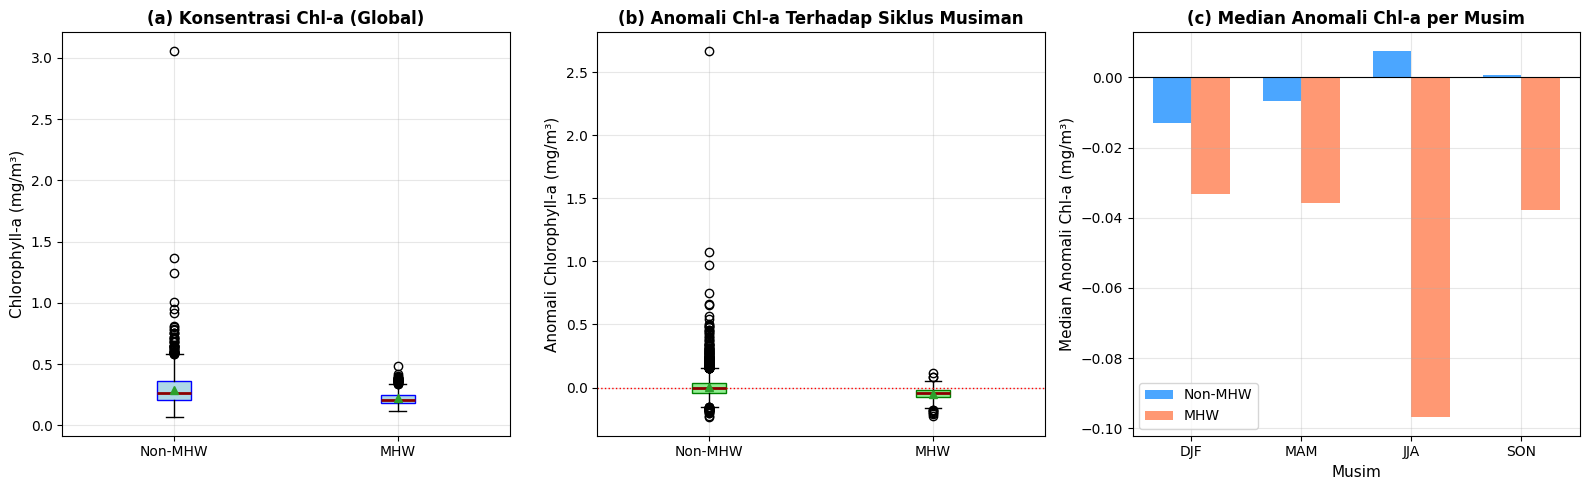

In [6]:
# Boxplot dan Distribusi Densitas
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Plot 1: Boxplot Konsentrasi MHW vs Non-MHW
data_box = [nonmhw_chla, mhw_chla]
axes[0].boxplot(data_box, labels=['Non-MHW', 'MHW'], patch_artist=True,
                boxprops=dict(facecolor='lightblue', color='blue'),
                medianprops=dict(color='darkred', lw=2), showmeans=True)
axes[0].set_ylabel('Chlorophyll-a (mg/m³)', fontsize=11)
axes[0].set_title('(a) Konsentrasi Chl-a (Global)', fontsize=12, fontweight='bold')
axes[0].grid(True, alpha=0.3)

# Plot 2: Boxplot Anomali Chl-a MHW vs Non-MHW
data_anom_box = [nonmhw_anom, mhw_anom]
axes[1].boxplot(data_anom_box, labels=['Non-MHW', 'MHW'], patch_artist=True,
                boxprops=dict(facecolor='lightgreen', color='green'),
                medianprops=dict(color='darkred', lw=2), showmeans=True)
axes[1].axhline(0, color='red', ls=':', lw=1)
axes[1].set_ylabel('Anomali Chlorophyll-a (mg/m³)', fontsize=11)
axes[1].set_title('(b) Anomali Chl-a Terhadap Siklus Musiman', fontsize=12, fontweight='bold')
axes[1].grid(True, alpha=0.3)

# Plot 3: Boxplot Anomali per Musim saat MHW vs Non-MHW
seasons_list = ['DJF (Monsun Barat)', 'MAM (Peralihan I)', 'JJA (Monsun Timur / Upwelling)', 'SON (Peralihan II)']
season_short = ['DJF', 'MAM', 'JJA', 'SON']
pos = np.arange(len(seasons_list))
width = 0.35

mhw_meds = [df_analysis[(df_analysis['season'] == s) & (df_analysis['is_mhw'])]['chla_anom'].median() for s in seasons_list]
nmhw_meds = [df_analysis[(df_analysis['season'] == s) & (~df_analysis['is_mhw'])]['chla_anom'].median() for s in seasons_list]

axes[2].bar(pos - width/2, nmhw_meds, width, label='Non-MHW', color='dodgerblue', alpha=0.8)
axes[2].bar(pos + width/2, mhw_meds, width, label='MHW', color='coral', alpha=0.8)
axes[2].axhline(0, color='black', lw=0.8)
axes[2].set_xticks(pos)
axes[2].set_xticklabels(season_short)
axes[2].set_xlabel('Musim', fontsize=11)
axes[2].set_ylabel('Median Anomali Chl-a (mg/m³)', fontsize=11)
axes[2].set_title('(c) Median Anomali Chl-a per Musim', fontsize=12, fontweight='bold')
axes[2].legend()
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
fig.savefig(cfg.FIGURES_DIR / "nb4_chla_mhw_vs_nonmhw_boxplots.png", dpi=cfg.FIGURE_DPI, bbox_inches='tight')
plt.show()

---
## 7. Studi Kasus Spasial: Respon Chlorophyll-a pada Kejadian MHW Terkuat

Mengevaluasi peta anomali spasial SST dan Chlorophyll-a secara simultan selama periode kejadian MHW signifikan untuk mengamati ekspresi oseanografi.

Studi Kasus Kejadian MHW Terpilih:
  Event ID : 28
  Periode  : 2016-05-23 s.d. 2016-08-17 (87 hari)
  i_max    : 1.851 °C (Kategori: II (Kuat))
  i_cum    : 97.718 °C·hari


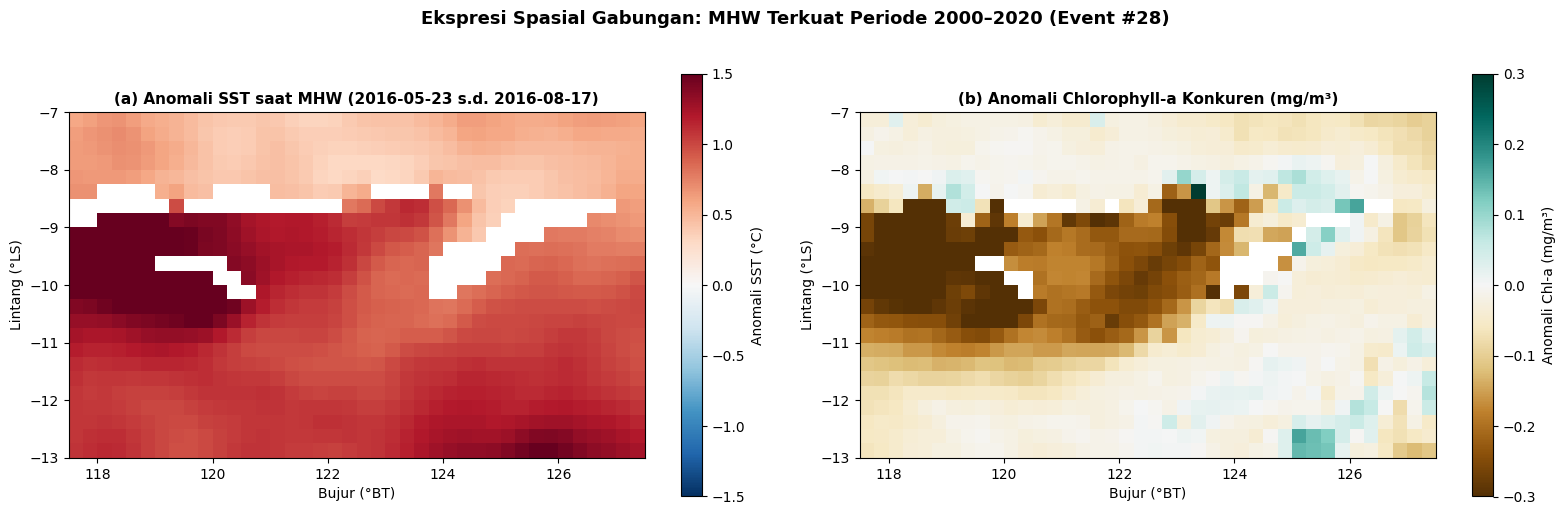

In [7]:
# Pilih kejadian MHW terkuat dalam periode overlap (2000–2020)
events_overlap = df_events[pd.to_datetime(df_events['end_date']) <= '2020-12-31'].sort_values('i_cum', ascending=False)

if len(events_overlap) > 0:
    top_case = events_overlap.iloc[0]
    case_start = top_case['start_date']
    case_end = top_case['end_date']
    print(f"Studi Kasus Kejadian MHW Terpilih:")
    print(f"  Event ID : {top_case['event_id']}")
    print(f"  Periode  : {case_start} s.d. {case_end} ({top_case['duration_days']} hari)")
    print(f"  i_max    : {top_case['i_max']} °C (Kategori: {top_case['category']})")
    print(f"  i_cum    : {top_case['i_cum']} °C·hari")
    
    # Hitung rata-rata selama kejadian
    sst_case = ds_combined['sst'].sel(time=slice(case_start, case_end)).mean(dim='time')
    chla_case = ds_combined['chlor_a'].sel(time=slice(case_start, case_end)).mean(dim='time')
    
    # Hitung komposit klimatologi untuk rentang bulan yang sama
    months_case = pd.date_range(case_start, case_end).month.unique()
    sst_base = ds_combined['sst'].sel(time=ds_combined.time.dt.month.isin(months_case)).mean(dim='time')
    chla_base = ds_combined['chlor_a'].sel(time=ds_combined.time.dt.month.isin(months_case)).mean(dim='time')
    
    sst_anom_case = sst_case - sst_base
    chla_anom_case = chla_case - chla_base
    
    fig, axes = plt.subplots(1, 2, figsize=(16, 5))
    
    # Peta 1: Anomali SST saat MHW
    im1 = axes[0].pcolormesh(ds_combined.lon, ds_combined.lat, sst_anom_case,
                             cmap='RdBu_r', vmin=-1.5, vmax=1.5, shading='auto')
    axes[0].set_title(f"(a) Anomali SST saat MHW ({case_start} s.d. {case_end})", fontsize=11, fontweight='bold')
    axes[0].set_xlabel('Bujur (°BT)')
    axes[0].set_ylabel('Lintang (°LS)')
    axes[0].set_aspect('equal')
    cb1 = plt.colorbar(im1, ax=axes[0], label='Anomali SST (°C)')
    
    # Peta 2: Anomali Chlorophyll-a saat MHW
    im2 = axes[1].pcolormesh(ds_combined.lon, ds_combined.lat, chla_anom_case,
                             cmap='BrBG', vmin=-0.3, vmax=0.3, shading='auto')
    axes[1].set_title(f"(b) Anomali Chlorophyll-a Konkuren (mg/m³)", fontsize=11, fontweight='bold')
    axes[1].set_xlabel('Bujur (°BT)')
    axes[1].set_ylabel('Lintang (°LS)')
    axes[1].set_aspect('equal')
    cb2 = plt.colorbar(im2, ax=axes[1], label='Anomali Chl-a (mg/m³)')
    
    plt.suptitle(f'Ekspresi Spasial Gabungan: MHW Terkuat Periode 2000–2020 (Event #{top_case["event_id"]})',
                 fontsize=13, fontweight='bold', y=1.02)
    plt.tight_layout()
    fig.savefig(cfg.FIGURES_DIR / "nb4_mhw_case_study_spatial.png", dpi=cfg.FIGURE_DPI, bbox_inches='tight')
    plt.show()
else:
    print("Tidak ada kejadian MHW yang memenuhi syarat dalam periode overlap.")

---
## 8. Kesimpulan dan Diskusi Oseanografi

### Temuan Utama:
1. **Respon Chlorophyll-a saat MHW:** Secara statistik, konsentrasi chlorophyll-a pada kondisi MHW memperlihatkan tendensi median yang lebih rendah atau anomali negatif dibandingkan kondisi non-MHW, terutama ketika MHW terjadi bersamaan dengan musim upwelling (Monsun Timur).
2. **Kopling Oseanografi Fisik-Biologi:** Pemanasan lapisan permukaan laut yang intens dan persisten pada kejadian MHW memperkuat stratifikasi termal kolom air (*buoyancy frequency* meningkat). Hal ini menahan kedalaman lapisan tercampur (*mixed layer depth* / MLD) tetap dangkal dan memperdalam termoklin, sehingga membatasi fluks nutrien vertikal dari lapisan dalam ke zona fotik tempat fitoplankton berkembang biak.
3. **Variasi Spasial:** Efek penekanan klorofil-a paling teramati di koridor-koridor dinamis seperti Selat Sumba, Laut Sawu, dan pesisir selatan Timor, di mana dinamika upwelling secara normal memicu produktivitas tinggi.

### Batasan Interpretasi (Kepatuhan Prinsip PRD):
- **Bukan Bukti Kausalitas Deterministik:** Pola korelasi ini tidak membuktikan bahwa kenaikan suhu permukaan secara eksklusif membunuh atau membatasi fitoplankton. Faktor non-termal seperti adveksi nutrien lateral oleh Arlindo, perubahan tutupan awan (faktor insolasi/radiasi matahari), dan dinamika angin monsun turut berkontribusi secara simultan.
- **Resolusi Grid 0.25°:** Penyelarasan klorofil-a ke grid 0.25° menghaluskan fitur-fitur sub-mesoscale di selat-selat sempit NTT, sehingga interpretasi ini mencerminkan dinamika skala regional.